In [1]:
from pathlib import Path
from datetime import timedelta, timezone
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

DATA_FILE = Path("wichita_weather_2020_2025.csv")
START_2024 = pd.Timestamp("2024-01-01", tz="America/Chicago")
START_2025 = pd.Timestamp("2025-01-01", tz="America/Chicago")
HORIZONS = [1, 6, 12, 24]
FEATURES = [
    "temperature", "humidity", "temp_1h_ago", "temp_3h_ago",
    "temp_6h_ago", "temp_24h_ago", "humidity_1h_ago",
    "humidity_3h_ago", "humidity_6h_ago", "hour", "day_of_year"
]
TARGETS = [f"target_{h}h" for h in HORIZONS]

In [2]:
df = pd.read_csv(DATA_FILE, skiprows=3).rename(columns={
    "temperature_2m (°C)": "temperature",
    "relative_humidity_2m (%)": "humidity"
})
df["time"] = (
    pd.to_datetime(df["time"])
    .dt.tz_localize(timezone(timedelta(hours=-7)))
    .dt.tz_convert("America/Chicago")
)
df = df.sort_values("time").reset_index(drop=True)
assert df["time"].is_unique
assert df[["time", "temperature", "humidity"]].notna().all().all()
assert (df["time"].diff().dropna() == pd.Timedelta(hours=1)).all()
print("Dataset shape:", df.shape)
print("Missing values:\n", df.isna().sum())
print("\nFirst five rows:\n", df.head().to_string(index=False))
print("\nSummary:\n", df[["temperature", "humidity"]].describe())

Dataset shape: (52608, 3)
Missing values:
 time           0
temperature    0
humidity       0
dtype: int64

First five rows:
                      time  temperature  humidity
2020-01-01 01:00:00-06:00         -1.4        78
2020-01-01 02:00:00-06:00         -1.4        78
2020-01-01 03:00:00-06:00         -2.4        80
2020-01-01 04:00:00-06:00         -0.9        77
2020-01-01 05:00:00-06:00         -1.1        76

Summary:
         temperature      humidity
count  52608.000000  52608.000000
mean      14.640201     64.568317
std       11.272967     19.402155
min      -28.100000      6.000000
25%        6.100000     50.000000
50%       15.700000     66.000000
75%       23.500000     80.000000
max       40.800000    100.000000


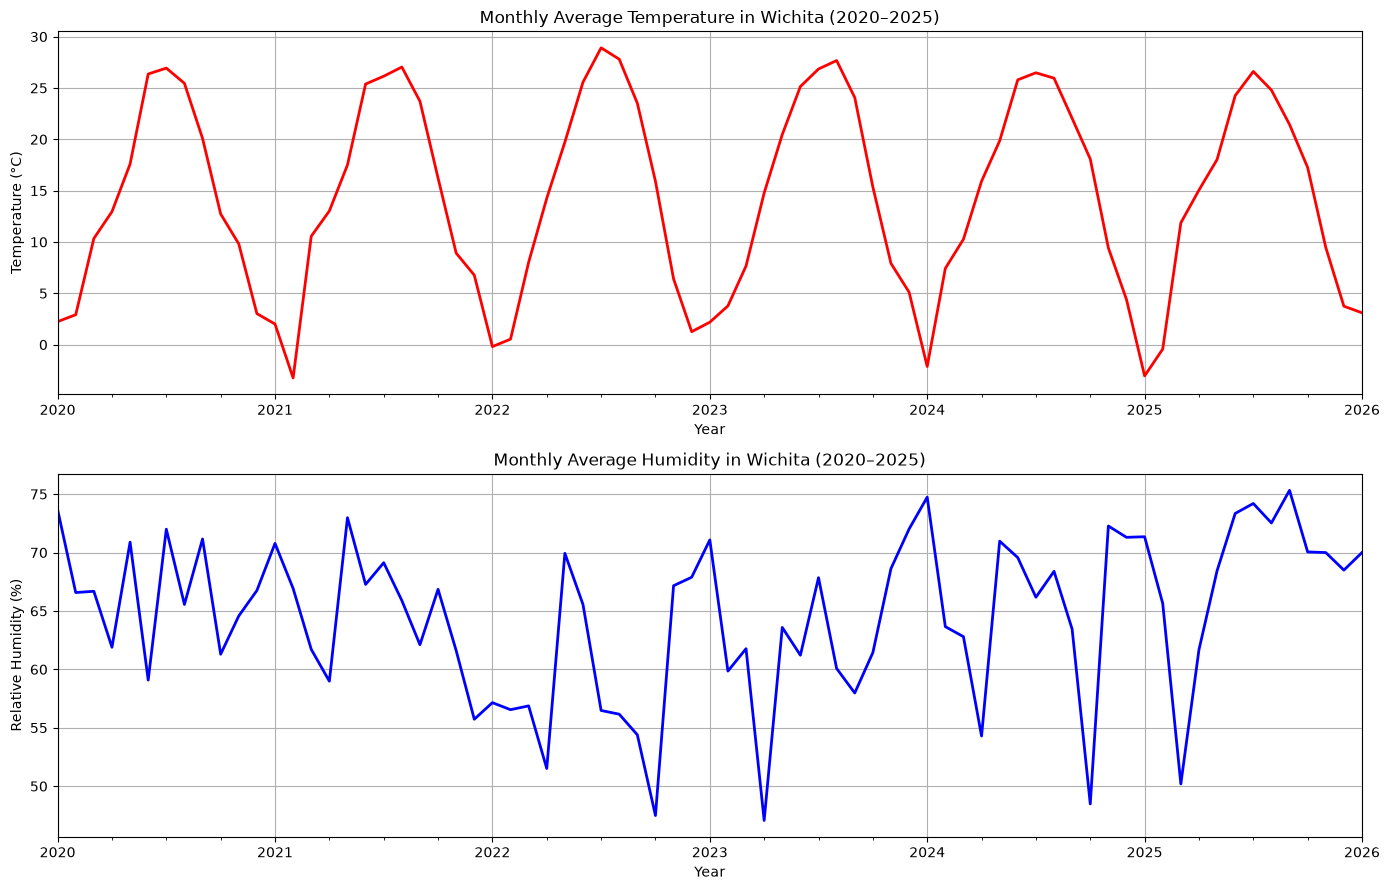

In [3]:
monthly = df.set_index("time")[["temperature", "humidity"]].resample("MS").mean()
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
monthly["temperature"].plot(ax=axes[0], color="red", linewidth=2)
axes[0].set(title="Monthly Average Temperature in Wichita (2020–2025)", xlabel="Year", ylabel="Temperature (°C)")
axes[0].grid(True)
monthly["humidity"].plot(ax=axes[1], color="blue", linewidth=2)
axes[1].set(title="Monthly Average Humidity in Wichita (2020–2025)", xlabel="Year", ylabel="Relative Humidity (%)")
axes[1].grid(True)
plt.tight_layout()
plt.show()

In [4]:
feature_df = df.copy()
for lag in [1, 3, 6, 24]:
    feature_df[f"temp_{lag}h_ago"] = feature_df["temperature"].shift(lag)
for lag in [1, 3, 6]:
    feature_df[f"humidity_{lag}h_ago"] = feature_df["humidity"].shift(lag)
feature_df["hour"] = feature_df["time"].dt.hour
feature_df["day_of_year"] = feature_df["time"].dt.dayofyear
for horizon in HORIZONS:
    feature_df[f"target_{horizon}h"] = feature_df["temperature"].shift(-horizon)
    feature_df[f"previous_day_{horizon}h"] = feature_df["temperature"].shift(24 - horizon)

single_df = feature_df.dropna(subset=FEATURES + ["target_6h"]).reset_index(drop=True)
multi_df = feature_df.dropna(subset=FEATURES + TARGETS).reset_index(drop=True)
print("Single-output dataset:", single_df.shape)
print("Multi-output dataset:", multi_df.shape)
print(multi_df[["time", "temperature"] + TARGETS].head().to_string(index=False))

Single-output dataset: (52578, 20)
Multi-output dataset: (52560, 20)
                     time  temperature  target_1h  target_6h  target_12h  target_24h
2020-01-02 01:00:00-06:00          4.3        4.0        1.8         9.0         3.4
2020-01-02 02:00:00-06:00          4.0        2.5        2.7        10.4         3.0
2020-01-02 03:00:00-06:00          2.5        1.1        4.3        11.5         2.2
2020-01-02 04:00:00-06:00          1.1        1.2        5.8         9.8         0.1
2020-01-02 05:00:00-06:00          1.2        1.8        7.3         9.0        -0.3


In [5]:
def split_periods(data, max_horizon):
    future_time = data["time"] + pd.Timedelta(hours=max_horizon)
    train = data[future_time < START_2024].copy()
    validation = data[(data["time"] >= START_2024) & (future_time < START_2025)].copy()
    test = data[data["time"] >= START_2025].copy()
    return train, validation, test

def metrics(name, actual, predicted):
    return {
        "Model": name,
        "MAE (°C)": round(mean_absolute_error(actual, predicted), 3),
        "RMSE (°C)": round(np.sqrt(mean_squared_error(actual, predicted)), 3),
        "R²": round(r2_score(actual, predicted), 4)
    }

train_df, val_df, test_df = split_periods(single_df, 6)
X_train, y_train = train_df[FEATURES], train_df["target_6h"]
X_val, y_val = val_df[FEATURES], val_df["target_6h"]
X_test, y_test = test_df[FEATURES], test_df["target_6h"]
print("6-hour training:", X_train.shape, y_train.shape)
print("6-hour validation:", X_val.shape, y_val.shape)
print("6-hour testing:", X_test.shape, y_test.shape)

6-hour training: (35033, 11) (35033,)
6-hour validation: (8778, 11) (8778,)
6-hour testing: (8755, 11) (8755,)


In [6]:
models = {
    "Linear Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(
        n_estimators=100, max_depth=12, min_samples_leaf=3,
        random_state=42, n_jobs=-1
    ),
    "Neural Network": Pipeline([
        ("scaler", StandardScaler()),
        ("neural_network", MLPRegressor(
            hidden_layer_sizes=(32, 16), activation="relu",
            solver="adam", max_iter=500, random_state=42
        ))
    ])
}
for name, model in models.items():
    model.fit(X_train, y_train)

validation_predictions = {name: model.predict(X_val) for name, model in models.items()}
validation_metrics = pd.DataFrame([
    metrics("Baseline", y_val, X_val["temperature"]),
    *[metrics(name, y_val, prediction) for name, prediction in validation_predictions.items()]
])
print("2024 validation, 6-hour forecast:\n", validation_metrics.to_string(index=False))

2024 validation, 6-hour forecast:
             Model  MAE (°C)  RMSE (°C)     R²
         Baseline     4.832      5.956 0.6948
Linear Regression     3.326      4.208 0.8476
    Random Forest     1.890      2.582 0.9426
   Neural Network     1.741      2.390 0.9509


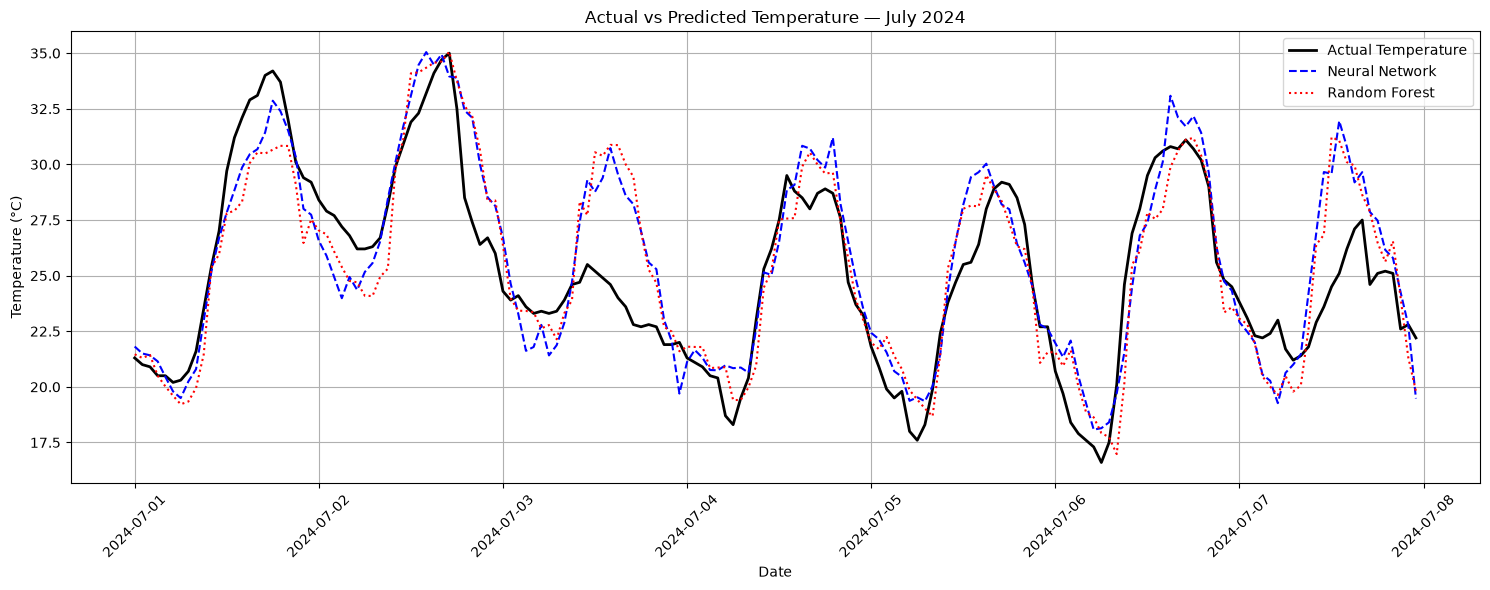

In [7]:
week_start = pd.Timestamp("2024-07-01", tz="America/Chicago")
week_end = pd.Timestamp("2024-07-08", tz="America/Chicago")
selected = (val_df["time"] + pd.Timedelta(hours=6)).between(week_start, week_end, inclusive="left").to_numpy()
forecast_times = val_df.loc[selected, "time"] + pd.Timedelta(hours=6)
plt.figure(figsize=(15, 6))
plt.plot(forecast_times, y_val.to_numpy()[selected], label="Actual Temperature", color="black", linewidth=2)
plt.plot(forecast_times, validation_predictions["Neural Network"][selected], label="Neural Network", color="blue", linestyle="--")
plt.plot(forecast_times, validation_predictions["Random Forest"][selected], label="Random Forest", color="red", linestyle=":")
plt.title("Actual vs Predicted Temperature — July 2024")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [8]:
test_predictions = {name: model.predict(X_test) for name, model in models.items()}
test_metrics = pd.DataFrame([
    metrics("Baseline", y_test, X_test["temperature"]),
    *[metrics(name, y_test, prediction) for name, prediction in test_predictions.items()]
])
print("2025 testing, 6-hour forecast:\n", test_metrics.to_string(index=False))

2025 testing, 6-hour forecast:
             Model  MAE (°C)  RMSE (°C)     R²
         Baseline     4.504      5.584 0.7588
Linear Regression     3.296      4.160 0.8661
    Random Forest     1.958      2.727 0.9425
   Neural Network     1.811      2.492 0.9520


In [9]:
train_multi, val_multi, test_multi = split_periods(multi_df, 24)
X_train_multi, y_train_multi = train_multi[FEATURES], train_multi[TARGETS]
X_val_multi, y_val_multi = val_multi[FEATURES], val_multi[TARGETS]
X_test_multi, y_test_multi = test_multi[FEATURES], test_multi[TARGETS]
print("Multi-output training:", X_train_multi.shape, y_train_multi.shape)
print("Multi-output validation:", X_val_multi.shape, y_val_multi.shape)
print("Multi-output testing:", X_test_multi.shape, y_test_multi.shape)

multi_nn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("neural_network", MLPRegressor(
        hidden_layer_sizes=(32, 16), activation="relu",
        solver="adam", max_iter=500, random_state=42
    ))
])
multi_nn_model.fit(X_train_multi, y_train_multi)
multi_predictions = multi_nn_model.predict(X_val_multi)
print("Multi-output model trained successfully")

Multi-output training: (35015, 11) (35015, 4)
Multi-output validation: (8760, 11) (8760, 4)
Multi-output testing: (8737, 11) (8737, 4)
Multi-output model trained successfully


In [10]:
def horizon_results(data, truth, predictions):
    records = []
    for i, horizon in enumerate(HORIZONS):
        actual = truth.iloc[:, i]
        pred = predictions[:, i]
        baseline = data["temperature"]
        previous_day = data[f"previous_day_{horizon}h"]
        baseline_mae = mean_absolute_error(actual, baseline)
        neural_mae = mean_absolute_error(actual, pred)
        records.append({
            "Forecast": f"+{horizon}h",
            "Baseline MAE": round(baseline_mae, 3),
            "Previous-Day MAE": round(mean_absolute_error(actual, previous_day), 3),
            "Neural Network MAE": round(neural_mae, 3),
            "RMSE": round(np.sqrt(mean_squared_error(actual, pred)), 3),
            "R²": round(r2_score(actual, pred), 4),
            "Improvement (%)": round((baseline_mae - neural_mae) / baseline_mae * 100, 2)
        })
    return pd.DataFrame(records)

validation_results = horizon_results(val_multi, y_val_multi, multi_predictions)
print("2024 multi-output validation:\n", validation_results.to_string(index=False))

2024 multi-output validation:
 Forecast  Baseline MAE  Previous-Day MAE  Neural Network MAE  RMSE     R²  Improvement (%)
     +1h         0.963             3.311               0.601 0.792 0.9946            37.61
     +6h         4.839             3.311               1.808 2.447 0.9484            62.63
    +12h         6.757             3.313               2.410 3.227 0.9102            64.34
    +24h         3.325             3.325               2.990 3.966 0.8642            10.10


In [11]:
multi_test_predictions = multi_nn_model.predict(X_test_multi)
final_results_df = horizon_results(test_multi, y_test_multi, multi_test_predictions)
print("2025 multi-output testing:\n", final_results_df.to_string(index=False))

2025 multi-output testing:
 Forecast  Baseline MAE  Previous-Day MAE  Neural Network MAE  RMSE     R²  Improvement (%)
     +1h         0.922             3.390               0.670 0.885 0.9940            27.38
     +6h         4.496             3.390               1.852 2.523 0.9508            58.81
    +12h         6.274             3.389               2.530 3.448 0.9080            59.69
    +24h         3.393             3.393               3.131 4.174 0.8651             7.71


In [12]:
model_folder = Path("models")
model_folder.mkdir(exist_ok=True)
model_path = model_folder / "weather_multi_nn.pkl"
joblib.dump(multi_nn_model, model_path)
loaded_model = joblib.load(model_path)
loaded_predictions = loaded_model.predict(X_test_multi)
assert np.allclose(multi_test_predictions, loaded_predictions)
print("Saved model:", model_path.resolve())
print("Reloaded model matches original:", True)

Saved model: C:\Users\mpung\OneDrive\Documents\CS746\project\models\weather_multi_nn.pkl
Reloaded model matches original: True


In [13]:
def cpp_float(value):
    return f"{float(value):.9e}f"

def cpp_array(name, array):
    array = np.asarray(array, dtype=np.float32)
    if array.ndim == 1:
        return f"const float {name}[{array.size}] = {{{', '.join(map(cpp_float, array))}}};\n\n"
    rows, cols = array.shape
    lines = ["    {" + ", ".join(map(cpp_float, row)) + "}" for row in array]
    return f"const float {name}[{rows}][{cols}] = {{\n" + ",\n".join(lines) + "\n};\n\n"

scaler = loaded_model.named_steps["scaler"]
network = loaded_model.named_steps["neural_network"]
layer_sizes = [network.coefs_[0].shape[0]] + [weights.shape[1] for weights in network.coefs_]
assert layer_sizes == [11, 32, 16, 4]
assert network.out_activation_ == "identity"

output_folder = Path("esp32_weather_ai")
output_folder.mkdir(exist_ok=True)
output_file = output_folder / "weather_model.h"

with output_file.open("w", encoding="utf-8") as f:
    f.write("#pragma once\n\n")
    f.write(f"const int NUM_INPUTS = {layer_sizes[0]};\n")
    f.write(f"const int NUM_OUTPUTS = {layer_sizes[-1]};\n\n")
    f.write(cpp_array("input_mean", scaler.mean_))
    f.write(cpp_array("input_scale", scaler.scale_))
    for i, (weights, biases) in enumerate(zip(network.coefs_, network.intercepts_)):
        f.write(cpp_array(f"weights_{i}", weights))
        f.write(cpp_array(f"biases_{i}", biases))

parameter_count = sum(x.size for x in network.coefs_) + sum(x.size for x in network.intercepts_)
print("Exported:", output_file.resolve())
print("Network layers:", layer_sizes)
print("Trainable parameters:", parameter_count)

Exported: C:\Users\mpung\OneDrive\Documents\CS746\project\esp32_weather_ai\weather_model.h
Network layers: [11, 32, 16, 4]
Trainable parameters: 980


In [14]:
sample = X_test_multi.iloc[[100]]
inputs = sample.iloc[0].to_numpy(dtype=np.float32)
expected = loaded_model.predict(sample)[0].astype(np.float32)
test_file = output_folder / "test_vector.h"

with test_file.open("w", encoding="utf-8") as f:
    f.write("#pragma once\n\n")
    f.write(cpp_array("test_input", inputs))
    f.write(cpp_array("expected_output", expected))

print("Exported:", test_file.resolve())
for horizon, value in zip(HORIZONS, expected):
    print(f"+{horizon}h: {value:.3f} °C")

Exported: C:\Users\mpung\OneDrive\Documents\CS746\project\esp32_weather_ai\test_vector.h
+1h: -4.626 °C
+6h: -1.129 °C
+12h: 3.073 °C
+24h: -4.202 °C
